In [143]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_val_predict
from tqdm import tqdm
from scipy import stats

In [31]:
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/medical_insurance_dataset.csv'
df= pd.read_csv(path, header=None)
df.head(5)

,0,1,2,3,4,5,6
0,19,1,27.900,0,1,3,16884.92400
1,18,2,33.770,1,0,4,1725.55230
2,28,2,33.000,3,0,4,4449.46200
3,33,2,22.705,0,0,1,21984.47061
4,32,2,28.880,0,0,1,3866.85520


In [32]:
headers=['age', 'gender', 'bmi', 'no_of_children', 'smoker', 'region', 'charges']
df.columns=headers
df.head(5)

,age,gender,bmi,no_of_children,smoker,region,charges
0,19,1,27.900,0,1,3,16884.92400
1,18,2,33.770,1,0,4,1725.55230
2,28,2,33.000,3,0,4,4449.46200
3,33,2,22.705,0,0,1,21984.47061
4,32,2,28.880,0,0,1,3866.85520


In [65]:
df.replace('?', np.nan, inplace=True)

,age,gender,bmi,no_of_children,smoker,region,charges
0,19,1,27.900,0,1,3,16884.92
1,18,2,33.770,1,0,4,1725.55
2,28,2,33.000,3,0,4,4449.46
3,33,2,22.705,0,0,1,21984.47
4,32,2,28.880,0,0,1,3866.86
...,...,...,...,...,...,...,...
2767,47,1,45.320,1,0,4,8569.86
2768,21,1,34.600,0,0,3,2020.18
2769,19,2,26.030,1,1,1,16450.89
2770,23,2,18.715,0,0,1,21595.38


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2768 non-null   str    
 1   gender          2772 non-null   int64  
 2   bmi             2772 non-null   float64
 3   no_of_children  2772 non-null   int64  
 4   smoker          2765 non-null   str    
 5   region          2772 non-null   int64  
 6   charges         2772 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 151.7 KB


In [69]:
df.isnull().sum()

age               4
gender            0
bmi               0
no_of_children    0
smoker            7
region            0
charges           0
dtype: int64

In [92]:
df['age']=df['age'].astype('float')
mean=df['age'].mean()
df.fillna({'age': mean}, inplace=True)
mode=df['smoker'].mode()[0]
df.fillna({'smoker':mode}, inplace=True)
df['age']=df['age'].astype('int')
df['smoker']=df['smoker'].astype('int')
df.dtypes

age                 int64
gender              int64
bmi               float64
no_of_children      int64
smoker              int64
region              int64
charges           float64
dtype: object

In [94]:
df.isnull().sum()

age               0
gender            0
bmi               0
no_of_children    0
smoker            0
region            0
charges           0
dtype: int64

In [93]:
df.describe(include='all')

,age,gender,bmi,no_of_children,smoker,region,charges
count,2772.000000,2772.000000,2772.000000,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,1.507215,30.701349,1.101732,0.203463,2.559885,13261.369957
std,14.081459,0.500038,6.129449,1.214806,0.402647,1.130761,12151.768970
min,18.000000,1.000000,15.960000,0.000000,0.000000,1.000000,1121.870000
25%,26.000000,1.000000,26.220000,0.000000,0.000000,2.000000,4687.800000
50%,39.000000,2.000000,30.447500,1.000000,0.000000,3.000000,9333.015000
75%,51.000000,2.000000,34.770000,2.000000,0.000000,4.000000,16577.780000
max,64.000000,2.000000,53.130000,5.000000,1.000000,4.000000,63770.430000


In [95]:
df['charges']=df['charges'].round(2)

In [96]:
df.head(5)

,age,gender,bmi,no_of_children,smoker,region,charges
0,19,1,27.900,0,1,3,16884.92
1,18,2,33.770,1,0,4,1725.55
2,28,2,33.000,3,0,4,4449.46
3,33,2,22.705,0,0,1,21984.47
4,32,2,28.880,0,0,1,3866.86


(0.0, 54.9885)

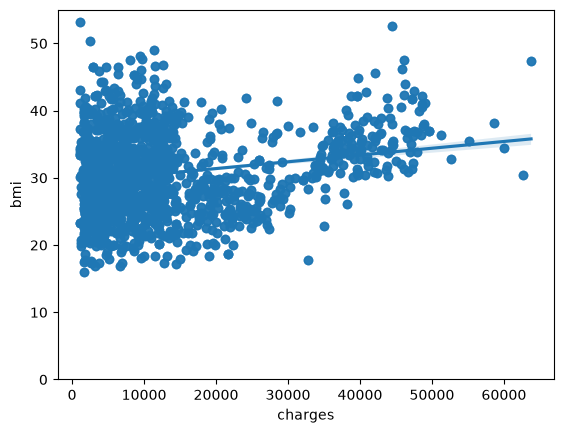

In [97]:
sns.regplot(x='charges', y='bmi', data=df)
plt.ylim(0,)

<Axes: xlabel='smoker', ylabel='charges'>

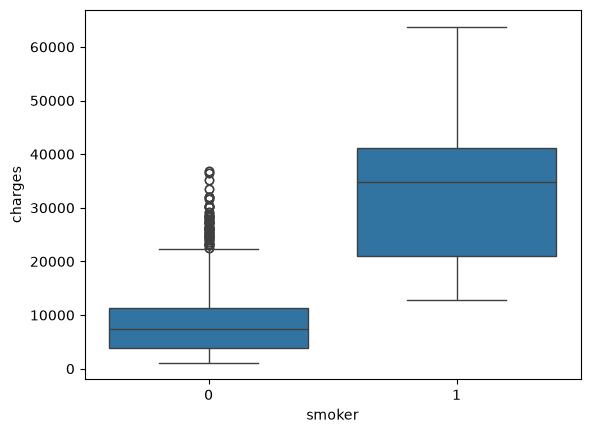

In [98]:
sns.boxplot(y='charges', x='smoker', data=df)

In [147]:
df['feature_zscore']= stats.zscore(df['smoker'])
df[['feature_zscore', 'smoker']].describe().round(2)

,feature_zscore,smoker
count,2772.00,2772.0
mean,-0.00,0.2
std,1.00,0.4
min,-0.51,0.0
25%,-0.51,0.0
50%,-0.51,0.0
75%,-0.51,0.0
max,1.98,1.0


In [114]:
corr_matrix=df.corr()
corr_matrix

,age,gender,bmi,no_of_children,smoker,region,charges
age,1.000000,-0.026046,0.113048,0.037574,-0.023286,-0.007167,0.298624
gender,-0.026046,1.000000,0.042924,0.016020,0.082326,0.022213,0.062837
bmi,0.113048,0.042924,1.000000,-0.001492,0.011489,0.271119,0.199846
no_of_children,0.037574,0.016020,-0.001492,1.000000,0.006362,-0.025717,0.066442
smoker,-0.023286,0.082326,0.011489,0.006362,1.000000,0.054077,0.788783
region,-0.007167,0.022213,0.271119,-0.025717,0.054077,1.000000,0.054058
charges,0.298624,0.062837,0.199846,0.066442,0.788783,0.054058,1.000000


<Axes: >

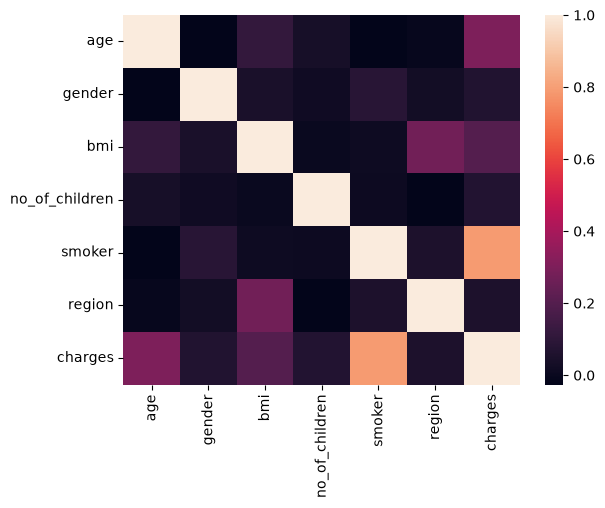

In [113]:
sns.heatmap(corr_matrix)

In [117]:
lr=LinearRegression()
lr.fit(df[['smoker']], df['charges'])
y_predict=lr.predict(df[['smoker']])
r2=r2_score(df['charges'], y_predict)
r2

0.6221791733924185

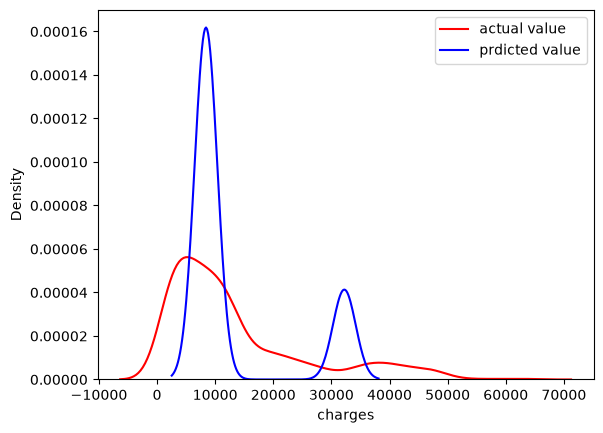

In [119]:
sns.kdeplot(data=df['charges'], color='r', label='actual value')
sns.kdeplot(data=y_predict, color='b', label="prdicted value")
plt.legend()
plt.show()

In [120]:
lr=LinearRegression()
Y= df['charges']
X=df.drop('charges', axis=1)
lr.fit(X, Y)
y_predict=lr.predict(X)
r2=r2_score(Y, y_predict)
r2

0.7504083820289634

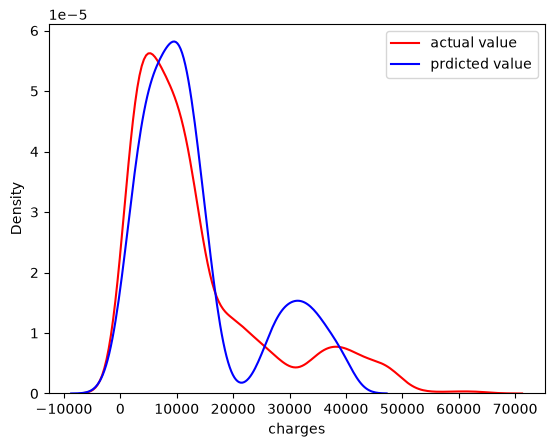

In [121]:
sns.kdeplot(data=df['charges'], color='r', label='actual value')
sns.kdeplot(data=y_predict, color='b', label="prdicted value")
plt.legend()
plt.show()

In [129]:
pipe=make_pipeline(
    PolynomialFeatures(),
    StandardScaler(),
    LinearRegression()
)

pipe.fit(X, Y)
y_predict=pipe.predict(X)
r2=r2_score(Y, y_predict)
r2

0.8452576213500093

In [132]:
x_train, x_test, y_train, y_test= train_test_split(X, Y, test_size=0.20, random_state=42)
x_train.shape[0], x_test.shape[0]

(2217, 555)

In [137]:
ridge=Ridge(alpha=0.1)

ridge.fit(x_train, y_train)
y_predict=ridge.predict(x_test)
r2=r2_score(y_test, y_predict)
r2

0.7395716463230874

In [138]:
pipe=make_pipeline(
    PolynomialFeatures(degree=2),
    StandardScaler(),
    Ridge(alpha=0.1)
)

pipe.fit(x_train, y_train)
y_predict=pipe.predict(x_test)
r2=r2_score(y_test, y_predict)
r2

0.8339370088841958